# MFASHA: Kinyarwanda Agricultural Chatbot
**ML Track – Initial Software Product (MVP)**

MFASHA answers farmers' questions in Kinyarwanda on crops, livestock, pests and diseases, and farm inputs/services. It uses a topic classifier and a hybrid retrieval engine over a knowledge base of agricultural passages, served through a Gradio web interface.

## Notebook contents
1. Setup and environment
2. Data loading and validation
3. Data engineering (labelling, cleaning, splitting)
4. Data visualization
5. Model architecture and training (topic classifier)
6. Retrieval engine and tuning
7. Out-of-scope handling (rejection threshold)
8. Performance summary
9. Demo and Gradio web app (MVP)
10. Deployment plan

## 1. Setup and environment
Installs the libraries and fixes the random seed (`SEED = 42`) so results are reproducible. The last lines print the Python and package versions used.

**Main libraries:** pandas, numpy, scikit-learn, rank_bm25, matplotlib, seaborn, huggingface_hub, joblib, gradio.

In [72]:
# installing the environments
!pip install -q rank_bm25 joblib

import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import csv, re, random, platform, warnings
from importlib.metadata import version
warnings.filterwarnings("ignore")

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
import sklearn
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics.pairwise import linear_kernel
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from rank_bm25 import BM25Okapi

# Dataset access
from huggingface_hub import list_repo_files, hf_hub_download

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Python          :", platform.python_version())
for pkg in ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn",
            "rank_bm25", "huggingface_hub", "joblib"]:
    print(f"{pkg:<16}:", version(pkg))
print("Seed            :", SEED)

Python          : 3.13.15
pandas          : 2.2.3
numpy           : 2.1.3
scikit-learn    : 1.6.1
matplotlib      : 3.10.0
seaborn         : 0.13.2
rank_bm25       : 0.2.2
huggingface_hub : 1.31.0
joblib          : 1.6.0
Seed            : 42


## Data loading

The repository contains (query, positive passage, negative passage) *triplets* as IDs, plus the question and answer texts. IDs look like `Q00487T001` (question) and `A020T001` (answer); the number after `T` is the **passage id** (`q_T`) that links a question to its answer. The `parsed_*` files are tokenised numeric versions for the authors' models and are not used here.

In [73]:
# Data source: locate the dataset and verify the files this notebook needs
REPO = "C4IR-RW/kinya-ag-retrieval"

files = list_repo_files(REPO, repo_type="dataset")

USED = [
    "rw_ag_retrieval_qpntriplets_train.tsv",   # (query id, positive id, negative id) triplets
    "rw_ag_retrieval_qpntriplets_dev.tsv",
    "rw_ag_retrieval_qpntriplets_test.tsv",
    "rw_ag_retrieval_questions.tsv",           # question id -> question text
    "rw_ag_retrieval_answers.tsv",             # answer id   -> passage text
]

missing = [f for f in USED if f not in files]
assert not missing, f"Missing dataset files: {missing}"

print("Files used by this notebook:")
for f in USED:
    print("   ", f)
print("\nFiles in the repository but not used (tokenised copies for the authors' models):")
for f in files:
    if f not in USED and f.startswith("parsed_"):
        print("   ", f)

# Print only the dataset facts we rely on, not the whole README
readme_path = hf_hub_download(REPO, "README.md", repo_type="dataset")
readme = open(readme_path, encoding="utf-8").read()
for line in readme.splitlines():
    if line.startswith(("license:", "pretty_name:")) or "passages" in line.lower() and "questions" in line.lower():
        print("README:", line.strip()[:200])

Files used by this notebook:
    rw_ag_retrieval_qpntriplets_train.tsv
    rw_ag_retrieval_qpntriplets_dev.tsv
    rw_ag_retrieval_qpntriplets_test.tsv
    rw_ag_retrieval_questions.tsv
    rw_ag_retrieval_answers.tsv

Files in the repository but not used (tokenised copies for the authors' models):
    parsed_rw_ag_retrieval_passage_text.txt
    parsed_rw_ag_retrieval_query_text.txt
README: pretty_name: Kinyarwanda Agricultural Retrieval Dataset
README: license: cc-by-4.0
README: The contains 984 kinyarwanda passages about different topics in agriculture and 19537 questions related to those passages.


In [74]:
# Load the authors' original (question, positive passage, negative passage) triplets
def load_tsv(filename):
    path = hf_hub_download(REPO, filename, repo_type="dataset")
    df = pd.read_csv(path, sep="\t", header=None, dtype=str)
    assert df.shape[1] == 3, f"{filename}: expected 3 columns, got {df.shape[1]}"
    return df

train_df = load_tsv("rw_ag_retrieval_qpntriplets_train.tsv")
dev_df   = load_tsv("rw_ag_retrieval_qpntriplets_dev.tsv")
test_df  = load_tsv("rw_ag_retrieval_qpntriplets_test.tsv")

n_total = 0
for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    n_q = d[0].nunique()
    n_total += n_q
    print(f"{name:<5}: {len(d):>9,} rows | {n_q:>6,} unique questions | {len(d) // n_q} rows per question")

print("\nTotal unique questions:", f"{n_total:,}")
assert n_total == 19537, "Question count does not match the dataset README (19,537)"
print("Matches the README count (19,537).")

train_df.head(5)

train: 1,901,200 rows | 19,012 unique questions | 100 rows per question
dev  :    19,600 rows |    196 unique questions | 100 rows per question
test :    32,900 rows |    329 unique questions | 100 rows per question

Total unique questions: 19,537
Matches the README count (19,537).


,0,1,2
0,Q00487T001,A020T001,A028T002
1,Q00487T001,A020T001,A029T003
2,Q00487T001,A020T001,A030T004
3,Q00487T001,A020T001,A031T005
4,Q00487T001,A020T001,A032T006


In [75]:
# Parse IDs. Format: Q00487T001 = question 487, passage id 1; A020T001 = answer 20, passage id 1
def parse_pairs(df):
    """One row per unique (question, positive passage) pair, with the passage id (q_T)."""
    pairs = df[[0, 1]].drop_duplicates().copy()
    pairs.columns = ["q", "pos"]
    pairs["q_id"]  = pairs["q"].str.extract(r"^Q(\d+)T")[0].astype(int)
    pairs["q_T"]   = pairs["q"].str.extract(r"T(\d+)$")[0].astype(int)
    pairs["pos_T"] = pairs["pos"].str.extract(r"T(\d+)$")[0].astype(int)
    return pairs

tr, dv, te = parse_pairs(train_df), parse_pairs(dev_df), parse_pairs(test_df)

for name, pairs_, raw in [("train", tr, train_df), ("dev", dv, dev_df), ("test", te, test_df)]:
    neg_T = raw[2].str.extract(r"T(\d+)$")[0].astype(int)
    q_T_of_row = raw[0].str.extract(r"T(\d+)$")[0].astype(int)
    print(f"--- {name} ---")
    print("unique questions               :", pairs_["q"].nunique())
    print("unique passages                :", pairs_["q_T"].nunique())
    print("question T == positive T       :", round((pairs_["q_T"] == pairs_["pos_T"]).mean(), 3))
    print("question T == negative T       :", round((q_T_of_row == neg_T).mean(), 3))

# Hard checks: the notebook depends on these assumptions
for name, pairs_ in [("train", tr), ("dev", dv), ("test", te)]:
    assert (pairs_["q_T"] == pairs_["pos_T"]).all(), f"{name}: question and positive passage ids differ"

# Leakage check on the authors' original split, by passage id
P = {n: set(p["q_T"]) for n, p in [("train", tr), ("dev", dv), ("test", te)]}
print("\nOriginal split, passages shared train/dev :", len(P["train"] & P["dev"]))
print("Original split, passages shared train/test:", len(P["train"] & P["test"]))
print("Original split, passages shared dev/test  :", len(P["dev"] & P["test"]))
print("Original split, questions shared train/test:", len(set(tr.q) & set(te.q)))

--- train ---
unique questions               : 19012
unique passages                : 941
question T == positive T       : 1.0
question T == negative T       : 0.0
--- dev ---
unique questions               : 196
unique passages                : 10
question T == positive T       : 1.0
question T == negative T       : 0.0
--- test ---
unique questions               : 329
unique passages                : 20
question T == positive T       : 1.0
question T == negative T       : 0.0

Original split, passages shared train/dev : 0
Original split, passages shared train/test: 0
Original split, passages shared dev/test  : 0
Original split, questions shared train/test: 0


In [76]:
# Load question and answer text, then build the two main tables:
def load_text_tsv(fname, cols):
    p = hf_hub_download(REPO, fname, repo_type="dataset")
    return pd.read_csv(p, sep="\t", header=None, names=cols, dtype=str,
                       quoting=csv.QUOTE_NONE, keep_default_na=False)

q_txt = load_text_tsv("rw_ag_retrieval_questions.tsv", ["q", "q_text"])
a_txt = load_text_tsv("rw_ag_retrieval_answers.tsv",   ["pos", "a_text"])
print("questions:", len(q_txt), "| unique ids:", q_txt.q.nunique())
print("answers  :", len(a_txt), "| unique ids:", a_txt.pos.nunique())

parts = []
for name, d in [("train", tr), ("dev", dv), ("test", te)]:
    p = d[["q", "pos", "q_T"]].copy()
    p["orig_split"] = name
    parts.append(p)
pairs = pd.concat(parts, ignore_index=True)

# validate= makes pandas raise an error if the merge would duplicate or drop rows
data = (pairs.merge(q_txt, on="q",   how="left", validate="one_to_one")
             .merge(a_txt, on="pos", how="left", validate="many_to_one"))

assert len(data) == len(pairs), "merge changed the number of rows"
assert data.q_text.notna().all() and data.a_text.notna().all(), "some IDs have no text"
assert data.groupby("q_T")["pos"].nunique().max() == 1, "a passage id maps to more than one answer text"

# One row per passage (the knowledge base)
passages = (data.drop_duplicates("q_T")[["pos", "q_T", "a_text"]]
            .reset_index(drop=True))

# Which answers in the file have no question linked to them?
a_T = a_txt["pos"].str.extract(r"T(\d+)$")[0].astype(int)
unused_T = set(a_T) - set(passages["q_T"])

print("\nPairs (questions)    :", len(data))
print("Distinct passages    :", len(passages))
print("Answers with no question (not used):", len(unused_T))
print("Questions per passage:", data.groupby("q_T").size().describe()[["min", "mean", "max"]].round(1).to_dict())
print("Start with 'Muraho'  :", round(data.q_text.str.startswith("Muraho").mean(), 3))
print("Question words       :", data.q_text.str.split().str.len().describe()[["mean", "50%", "max"]].round(1).to_dict())

data.sample(5, random_state=SEED)[["q_T", "q_text"]]

questions: 19537 | unique ids: 19537
answers  : 984 | unique ids: 984

Pairs (questions)    : 19537
Distinct passages    : 971
Answers with no question (not used): 13
Questions per passage: {'min': 1.0, 'mean': 20.1, 'max': 28.0}
Start with 'Muraho'  : 0.176
Question words       : {'mean': 11.0, '50%': 10.0, 'max': 44.0}


,q_T,q_text
5380,252,Indwara y' akaribata ni indwara ki ?
19411,598,mbere yuko imishwi iza mu biraro na nyuma yaho...
971,55,Ni gute wategura imborera mu buryo bw' ikirundo ?
2830,137,Ni ubuhe buryo bwo kurinda no kurwanya indwara...
12041,530,indwara y' ibivumvuri iyo yageze mu ntama bayi...


In [77]:
# Data quality check on the knowledge base
plen = passages["a_text"].str.split().str.len()
has_title = passages["a_text"].str.contains(":", regex=False)
dup_text = passages["a_text"].str.lower().str.strip().duplicated(keep=False)

print("Passages                          :", len(passages))
print("Words per passage (min/median/max):", plen.min(), "/", plen.median(), "/", plen.max())
print("Passages with a ':' title         :", int(has_title.sum()), f"({has_title.mean() * 100:.1f}%)")
print("Passages under 15 words           :", int((plen < 15).sum()))
print("Passages with duplicated text     :", int(dup_text.sum()))

print("\nShortest 5 passages:")
for _, r in passages.assign(n_words=plen).nsmallest(5, "n_words").iterrows():
    print(f"  T{r['q_T']} ({r['n_words']} words) | {r['a_text'][:120]}")

print("\nRandom sample of 10 passages:")
for _, r in passages.sample(10, random_state=SEED).iterrows():
    print(f"  T{r['q_T']} | {r['a_text'][:150]}")

Passages                          : 971
Words per passage (min/median/max): 6 / 79.0 / 498
Passages with a ':' title         : 693 (71.4%)
Passages under 15 words           : 36
Passages with duplicated text     : 0

Shortest 5 passages:
  T10 (6 words) | Ibitishingirwa ku gihingwa cy' umuceri :
  T14 (6 words) | Ibitishingirwa ku gihingwa cy' imiteja :
  T30 (6 words) | Ibitishingirwa ku gihingwa cy' ibirayi :
  T33 (6 words) | Ibyishingirwa ku gihingwa cy' urusenda :
  T229 (6 words) | Soya isarurwa mu buryo bukurikira :

Random sample of 10 passages:
  T191 | Uburyo bwo kwirinda no kurwanya indwara y' amabara akora inguni mubishyimbo ni ubu bukurikiraGutera imbuto ihungiye hakoreshejwe imiti nka Benomyl cya
  T897 | Ibidomo by' uruziga ( Papayaringspot virus ) y' ipapayi : Ibidomo by' uruziga n' indwara ya virusi irangwa n' ibidomo by' uruziga by' icyatsi kibisi c
  T94 | Indwara ya Kirabiranya y' ibigori irangwa n' ibi bikurikira : Amababi y' ikigori cyafashwe ahinduka umuhondo , a

In [78]:
# How many questions point to a heading-only passage?
short_T = set(passages.loc[plen < 15, "q_T"])
n_short_q = int(data["q_T"].isin(short_T).sum())
print(f"\nQuestions linked to passages under 15 words: {n_short_q} of {len(data)} ({n_short_q / len(data) * 100:.1f}%)")


Questions linked to passages under 15 words: 817 of 19537 (4.2%)


In [79]:
# Rule-based topic labels
TITLE_SEP = re.compile(r"[:;?]")

def get_title(text, max_chars=80):
    """Title = text before the first ':' ';' or '?', capped at max_chars (lower-cased)."""
    m = TITLE_SEP.search(text)
    head = text[:m.start()] if (m and m.start() > 0) else text
    return head[:max_chars].strip().lower()

def get_title_old(text):
    """Previous version (':' only, 100-char fallback). Kept only to measure what changed."""
    head = text.split(":", 1)[0] if ":" in text else text[:100]
    return head.strip().lower()

def norm(q):
    """Light normalisation: collapse whitespace and remove spaces before punctuation."""
    q = re.sub(r"\s+", " ", q).strip()
    return re.sub(r"\s+([?.!,;:])", r"\1", q)
ANIMAL = [r"\binka\b", r"\bmu nka\b", r"nkoko", r"ngurube", r"hene\b", r"ntama", r"matungo",
          r"kwavu",                      # rabbits: urukwavu, inkwavu, nkwavu
          r"mafi\b", r"bworozi", r"mishwi", r"kiraro", r"biraro", r"ntanga", r"bwatsi"]

PEST = [r"ndwara", r"nkongwa", r"kivumvuri", r"virusi", r"bidomo", r"kirabiranya", r"kabore",
        r"dukoko", r"gakoko", r"onnyi", r"imbaragasa", r"sazi", r"sasi", r"busimba", r"tsindika",
        r"inanda", r"bubembe", r"kurwanya", r"kwirinda",
        r"buhunduguru",                  # aphids ("aphids" is written in the passages)
        r"milidiyu|mildew",              # powdery mildew
        r"akaribata|anthracnose",        # anthracnose
        r"tiripusi",                     # thrips
        r"matirizi"]                     # utumatirizi (small insects on citrus)

RULES = [
    ("animal health", ANIMAL,
     [r"ndwara", r"rukingo", r"gukingira", r"virusi", r"umuti", r"kuvura", r"nzoka"]),
    ("livestock management", ANIMAL, None),
    ("inputs and services",
     [r"impushya", r"gahunda ya leta", r"ishingi", r"inshingi", r"ishingir", r"inguzanyo",
      r"koperative", r"uburobyi", r"minagri", r"isoko", r"ibiciro", r"igiciro", r"fumbire",
      r"ibinyabutabire"], None),
    ("crop pests and diseases", PEST, None),
]

def categorise(text, title_fn=None):
    t = (title_fn or get_title)(text)
    for cat, keys, extra in RULES:
        if any(re.search(k, t) for k in keys):
            if extra is None or any(re.search(e, t) for e in extra):
                return cat, True
    return "crop production (general)", False

res = passages["a_text"].apply(categorise)
passages["category"] = [r[0] for r in res]
passages["rule_matched"] = [r[1] for r in res]

# Keep a copy of the keyword-rule labels, before the manual exceptions in the next cell.
# This line lives here (not in the next cell) so re-running the next cell never loses the comparison.
passages["category_rules"] = passages["category"]

# What did the title fix change?
old_cat = passages["a_text"].apply(lambda x: categorise(x, get_title_old)[0])
title_changed = sum(get_title(t) != get_title_old(t) for t in passages["a_text"])
print("Passages whose extracted title changed :", title_changed)
print("Passages whose category changed        :", int((old_cat != passages["category"]).sum()))

print("\nCategory counts:")
print(passages["category"].value_counts())

# The passages whose category changed because of the new title rule
moved = passages.assign(old=old_cat)[old_cat != passages["category"]]
print("\nMoves (rows = old label, columns = new label):")
print(pd.crosstab(moved["old"], moved["category"]))
print()
for _, r in moved.iterrows():
    print(f"T{r.q_T} | {r.old[:14]} -> {r.category[:14]}")
    print(f"     old title: {get_title_old(r.a_text)[:70]}")
    print(f"     new title: {get_title(r.a_text)[:70]}")

print("\nRandom 20 from 'crop production (general)' (title the rules saw | start of text):")
g = passages[passages["category"] == "crop production (general)"]
for _, r in g.sample(20, random_state=3).iterrows():
    print(f"  T{r.q_T} | {get_title(r.a_text)[:60]} | {r.a_text[:60]}")

Passages whose extracted title changed : 478
Passages whose category changed        : 37

Category counts:
category
crop production (general)    488
crop pests and diseases      211
livestock management         148
inputs and services           70
animal health                 54
Name: count, dtype: int64

Moves (rows = old label, columns = new label):
category                 crop pests and diseases  crop production (general)  \
old                                                                           
animal health                                  2                          1   
crop pests and diseases                        0                         17   
inputs and services                            3                          8   
livestock management                           0                          2   

category                 inputs and services  livestock management  
old                                                                 
animal health                   

In [80]:

def categorise_final(text):
    """Returns (category, matched, rule_name). rule_name says which manual exception fired."""
    head  = text[:200].lower()
    title = get_title(text)
    if re.search(r"ndwara ikingirwa|inkingo", head) and re.search(r"new castle|inkoko|bronchitis", head):
        return "animal health", True, "vaccination table"
    if re.search(r"gishorobwa|shorobwa", title):
        return "crop pests and diseases", True, "gishorobwa"
    if re.search(r"gutwara umusaruro|amasoko", title):
        return "inputs and services", True, "markets / transport"
    cat, matched = categorise(text)
    return cat, matched, "keyword rules"

res = passages["a_text"].apply(categorise_final)
passages["category"]     = [r[0] for r in res]
passages["rule_matched"] = [r[1] for r in res]
passages["rule_used"]    = [r[2] for r in res]

changed = passages[passages["category"] != passages["category_rules"]]
print("Passages changed by the manual exceptions:", len(changed))
print(changed["rule_used"].value_counts().to_string())

print("\nPassages changed (check these by eye):")
for _, r in changed.iterrows():
    print(f"  T{r.q_T} | {r.category_rules[:14]} -> {r.category[:14]} | {r.rule_used} | {get_title(r.a_text)[:60]}")

print("\nFinal category counts:")
print(passages["category"].value_counts())
print("\nShare of passages by category (%):")
print((passages["category"].value_counts(normalize=True) * 100).round(1))

passages[["pos", "q_T", "category"]].to_csv("passage_categories.csv", index=False)


Passages changed by the manual exceptions: 11
rule_used
vaccination table      9
gishorobwa             1
markets / transport    1

Passages changed (check these by eye):
  T450 | crop productio -> crop pests and | gishorobwa | ibimenyetso by' igishorobwa ( cockhafer grub ) cy' igihingwa
  T579 | livestock mana -> animal health | vaccination table | ibigwana by' inkoko z' amagi
  T586 | crop productio -> animal health | vaccination table | iminsi
  T588 | crop productio -> animal health | vaccination table | iminsi
  T590 | crop productio -> animal health | vaccination table | iminsi
  T591 | crop productio -> animal health | vaccination table | iminsi
  T592 | crop productio -> animal health | vaccination table | iminsi
  T593 | crop productio -> animal health | vaccination table | iminsi
  T594 | crop productio -> animal health | vaccination table | iminsi
  T595 | crop productio -> animal health | vaccination table | iminsi
  T802 | crop productio -> inputs and ser | markets / trans

In [81]:
# Question cleaning
INTRO = re.compile(
    r"^\s*(muraho|mwaramutse|mwiriwe|bonjour|hello)\b[^?]*?"
    r"\b(ndashaka|nshaka|nashakaga|nashaka|dushaka|nifuza|nifuzaga|dufuza|ndabaza|nabaza)\s+"
    r"(ko\s+|nti\s+)?(mumbwira|munsobanurire|kubasobanuza|kubabaza|kubaza|kumenya|gusobanuza|kubasobanurira)?\s*",
    flags=re.IGNORECASE)

BARE = re.compile(r"^\s*(muraho|mwaramutse|mwiriwe)( neza)?\s*[!,.]*\s*"
                  r"(mwamfasha|nabaza|mumbwire)?\s*(kumenya\s+)?", flags=re.IGNORECASE)

def clean_question_v2(q):
    q2 = INTRO.sub("", q).strip()
    if q2 == q.strip():
        q2 = BARE.sub("", q).strip()
    q2 = norm(q2)
    return q2 if len(q2.split()) >= 3 else norm(q)
starts = ("muraho", "mwaramutse", "mwiriwe", "bonjour", "hello")

data["q_clean"] = data["q_text"].apply(clean_question_v2)

was_greeting = data["q_text"].str.strip().str.lower().str.startswith(starts)
unchanged    = data["q_clean"] == data["q_text"].apply(norm)
fell_back    = was_greeting & unchanged

print("Questions starting with a greeting      :", int(was_greeting.sum()))
print("  cleaned                               :", int((was_greeting & ~unchanged).sum()))
print("  left as they were (too short/no match):", int(fell_back.sum()))
print("Non-greeting questions changed (must be 0):", int((~was_greeting & ~unchanged).sum()))

wb = data.loc[was_greeting, "q_text"].str.split().str.len().mean()
wa = data.loc[was_greeting, "q_clean"].str.split().str.len().mean()
print(f"\nWords per greeting question: {wb:.1f} before -> {wa:.1f} after")
print("Words in q_clean, all questions (mean):", round(data["q_clean"].str.split().str.len().mean(), 1))

print("\nSpot check, 6 random cleaned greeting questions:")
for _, r in data[was_greeting & ~unchanged].sample(6, random_state=7).iterrows():
    print("  BEFORE:", r.q_text[:130])
    print("  AFTER :", r.q_clean[:130], "\n")

print("Greeting questions that were left uncleaned:")
for _, r in data[fell_back].iterrows():
    print("  ", r.q_text[:140])


REMNANT = re.compile(r"\b(nitwa|ndi umuhinzi|ndi umworozi|ntuye|ndashaka|nshaka|"
                     r"nashakaga|nifuza|nifuzaga|ndabaza|kubabaza|kubaza|kubasobanuza)\b", re.IGNORECASE)
g = data[was_greeting]
still = g[g["q_clean"].apply(lambda s: bool(REMNANT.search(s)))]
print(f"\nGreeting questions with intro words still in q_clean: {len(still)} of {len(g)} ({len(still) / len(g) * 100:.1f}%)")
for _, r in still.sample(min(8, len(still)), random_state=1).iterrows():
    print("  ", r.q_clean[:130])

Questions starting with a greeting      : 3566
  cleaned                               : 3562
  left as they were (too short/no match): 4
Non-greeting questions changed (must be 0): 0

Words per greeting question: 18.0 before -> 8.3 after
Words in q_clean, all questions (mean): 8.3

Spot check, 6 random cleaned greeting questions:
  BEFORE: Muraho neza nitwa rukundo Moise ndashaka kubaza uburyo bwiza bwo gusarura no gufata neza imiteja ?
  AFTER : uburyo bwiza bwo gusarura no gufata neza imiteja? 

  BEFORE: Muraho neza nitwa rukundo ndi umuhinzi ndashaka kubasobanuza ni gute umuntu yarwanya uruhumbu rw' umweru ku myembe ?
  AFTER : ni gute umuntu yarwanya uruhumbu rw' umweru ku myembe? 

  BEFORE: Muraho neza nitwa Rujugiro Emanuel ndi umuhinzi mu karere ka Gisagara nshaka kubabaza ni gute bakuraho amababi ku biti bya Pome ?
  AFTER : ni gute bakuraho amababi ku biti bya Pome? 

  BEFORE: Muraho neza nitwa Cyogere ndi umworozi ndashaka kubabaza kuri gahunda yankunganire kubwishingizi 

In [82]:
# Label audit and manual corrections
ANIMAL_STEMS = r"inka|nkoko|ngurube|hene|ntama|matungo|kwavu|nzuki|mafi|girinka|bworozi|mishwi"
audit = passages[["q_T", "category", "a_text"]].copy()
audit["title"] = audit["a_text"].apply(get_title)
flag = audit[audit["title"].str.contains(ANIMAL_STEMS, regex=True)
             & audit["category"].isin(["crop production (general)", "crop pests and diseases"])]
print("Flagged for review:", len(flag), "of", len(audit), "passages")
for _, r in flag.iterrows():
    print(f"  T{r.q_T} | {r.category[:14]} | {r.title[:80]}")

# 2. Manual corrections, one passage at a time. Confirm these with a Kinyarwanda speaker.
OVERRIDES = {
    # Girinka programme -> inputs and services
    35: "inputs and services", 36: "inputs and services", 37: "inputs and services",
    40: "inputs and services", 41: "inputs and services", 43: "inputs and services",
    # Beekeeping -> livestock management
    543: "livestock management", 544: "livestock management",
    545: "livestock management", 546: "livestock management",
    # Coffee stem borer -> crop pests and diseases
    422: "crop pests and diseases", 423: "crop pests and diseases", 424: "crop pests and diseases",

    492: "animal health",
    579: "livestock management",
    802: "crop production (general)",
    875: "crop pests and diseases",
    961: "animal health",
    969: "animal health",
}

passages["category_before_overrides"] = passages["category"]
passages["category"] = [OVERRIDES.get(int(t), c) for t, c in zip(passages["q_T"], passages["category"])]

changed = passages[passages["category"] != passages["category_before_overrides"]]
print("\nOverrides listed:", len(OVERRIDES), "| passages whose label actually changed:", len(changed))
for _, r in changed.iterrows():
    print(f"  T{r.q_T} | {r.category_before_overrides[:14]} -> {r.category[:14]} | {get_title(r.a_text)[:60]}")

not_found = [t for t in OVERRIDES if t not in set(passages["q_T"])]
assert not not_found, f"Override ids not in the data: {not_found}"



Flagged for review: 14 of 971 passages
  T35 | crop productio | gahunda ya girinka munyarwanda yatangiye mu mwaka wa 2006 itangijwe na nyakubahw
  T36 | crop productio | gahunda ya girinka igamije koroza imiryango ikennye mu rwego rwo kwiteza imbere
  T37 | crop productio | imuryango yorozwa muri gahunda ya girinka munyarwanda ingomba kuba yujuje ibi bi
  T40 | crop productio | umuntu wese ujuririra urutonde rwa girinka abikora mu nyandiko mu gihe kitarenze
  T41 | crop productio | imiryango yose iri ku rutonde ndakuka rwa girinka inganya amahirwe yo korozwa in
  T43 | crop productio | gahunda y' ibikorwa bya girinka ikorwa muburyo bukurikira
  T422 | crop productio | inkangabashi n' ibivumvuri muri kawa
  T423 | crop productio | dore ibiranga inkangabashi y' umweru muri kawa
  T424 | crop productio | ibimenyetso by' inkangabarashi ku giti cya kawa
  T425 | crop pests and | kurwanya inkangabashi n' ibivumvuri ( stem borer )
  T543 | crop productio | umusaruro w' inzuki
  T544 | crop pr

In [83]:
# Attach the corrected labels to the question table
cat_map  = dict(zip(passages["q_T"], passages["category"]))
orig_map = dict(zip(passages["q_T"], passages["category_before_overrides"]))
data["category"]          = data["q_T"].map(cat_map)
data["category_original"] = data["q_T"].map(orig_map)
assert data["category"].notna().all()

print("Final category counts (passages):")
print(passages["category"].value_counts())
print("\nFinal category counts (questions):")
print(data["category"].value_counts())

passages[["pos", "q_T", "category_before_overrides"]].rename(
    columns={"category_before_overrides": "category"}).to_csv("passage_categories_original.csv", index=False)
passages[["pos", "q_T", "category"]].to_csv("passage_categories_corrected.csv", index=False)
print("\nSaved passage_categories_original.csv and passage_categories_corrected.csv (commit both).")

Final category counts (passages):
category
crop production (general)    465
crop pests and diseases      214
livestock management         151
inputs and services           76
animal health                 65
Name: count, dtype: int64

Final category counts (questions):
category
crop production (general)    9107
crop pests and diseases      4517
livestock management         2759
inputs and services          1758
animal health                1396
Name: count, dtype: int64

Saved passage_categories_original.csv and passage_categories_corrected.csv (commit both).


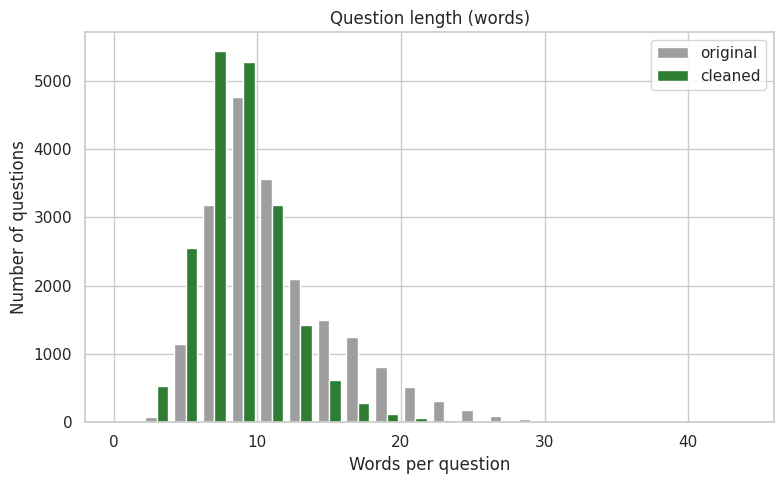

Questions without a split: 0
split
train    13885
dev       2850
test      2802
Name: count, dtype: int64
split
train    71.1
dev      14.6
test     14.3
Name: proportion, dtype: float64

Passage overlap train/dev : 0
Passage overlap train/test: 0
Passage overlap dev/test  : 0

Questions per category and split:
split                      train   dev  test
category                                    
animal health               1068   209   119
crop pests and diseases     3227   619   671
crop production (general)   6398  1431  1278
inputs and services         1325   217   216
livestock management        1867   374   518


In [84]:
#  Question length, before vs after cleaning
len_before = data["q_text"].str.split().str.len()
len_after  = data["q_clean"].str.split().str.len()
plt.hist([len_before, len_after], bins=range(0, 46, 2),
         label=["original", "cleaned"], color=["#9E9E9E", "#2E7D32"])
plt.title("Question length (words)")
plt.xlabel("Words per question"); plt.ylabel("Number of questions")
plt.legend(); plt.tight_layout()
plt.savefig("fig_question_length.png", dpi=150); plt.show()

psg = passages[["q_T", "category"]].reset_index(drop=True)

def one_fold(df, n_splits):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    tr_i, te_i = next(sgkf.split(df, df["category"], groups=df["q_T"]))
    return df.iloc[tr_i], df.iloc[te_i]

trainval_p, test_p = one_fold(psg, n_splits=7)
train_p, dev_p     = one_fold(trainval_p, n_splits=6)

split_of = {}
for name, d in [("train", train_p), ("dev", dev_p), ("test", test_p)]:
    for t in d["q_T"]:
        split_of[t] = name
data["split"] = data["q_T"].map(split_of)

print("Questions without a split:", data["split"].isna().sum())
print(data["split"].value_counts())
print((data["split"].value_counts(normalize=True) * 100).round(1))

S = {s: set(data.loc[data.split == s, "q_T"]) for s in ["train", "dev", "test"]}
print("\nPassage overlap train/dev :", len(S["train"] & S["dev"]))
print("Passage overlap train/test:", len(S["train"] & S["test"]))
print("Passage overlap dev/test  :", len(S["dev"] & S["test"]))
assert not (S["train"] & S["dev"]) and not (S["train"] & S["test"]) and not (S["dev"] & S["test"])
assert data["split"].notna().all()

q_per_class = pd.crosstab(data["category"], data["split"])[["train", "dev", "test"]]
print("\nQuestions per category and split:")
print(q_per_class)
assert (q_per_class > 0).all().all(), "a category is missing from a split"

# Shortcuts used by the later cells
tr_d = data[data.split == "train"]
dv_d = data[data.split == "dev"]
te_d = data[data.split == "test"]

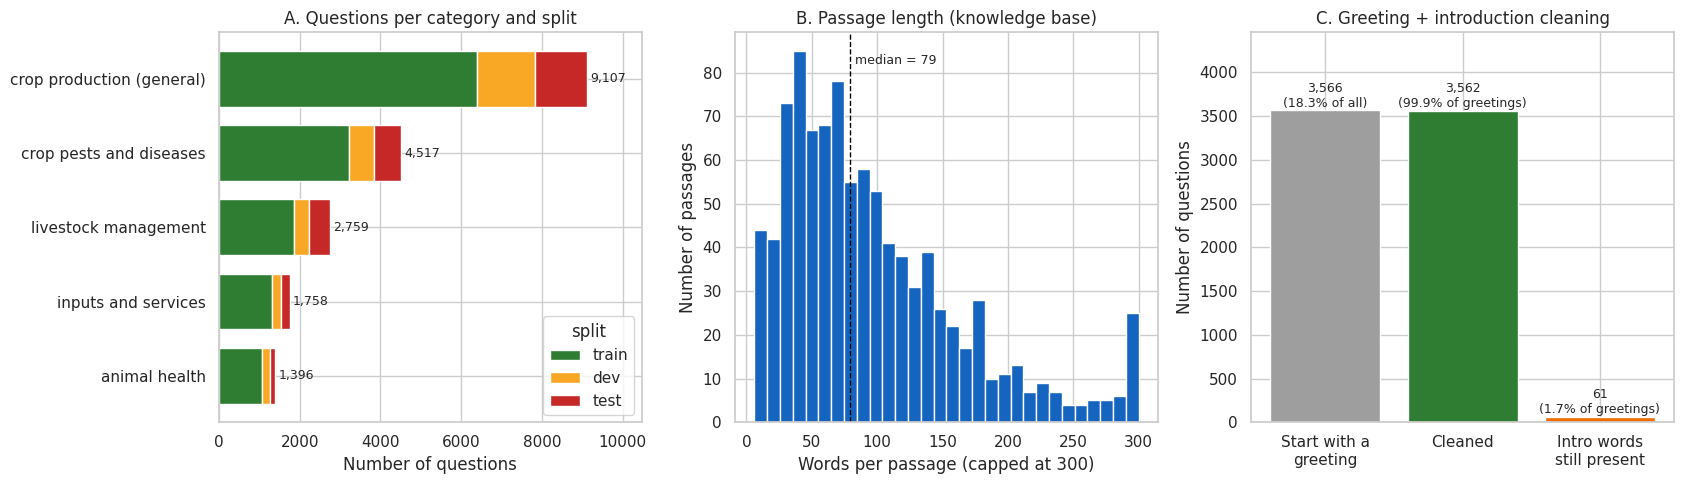

Questions with a greeting       : 3566 (18.3% of 19,537)
  cleaned                       : 3562
  intro words still present     : 61
Passage length median / max     : 79 / 498
Smallest class in test (questions): 119 -> animal health


In [85]:
# Data overview:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

order = data["category"].value_counts().index.tolist()
ct = (pd.crosstab(data["category"], data["split"])[["train", "dev", "test"]]
        .loc[order])
ct.plot(kind="barh", stacked=True, ax=axes[0],
        color=["#2E7D32", "#F9A825", "#C62828"], width=0.75)
axes[0].invert_yaxis()
axes[0].set_title("A. Questions per category and split")
axes[0].set_xlabel("Number of questions"); axes[0].set_ylabel("")
axes[0].legend(title="split", loc="lower right")
for i, total in enumerate(ct.sum(axis=1)):
    axes[0].text(total + 80, i, f"{total:,}", va="center", fontsize=9)
axes[0].set_xlim(0, ct.sum(axis=1).max() * 1.15)

# Panel B: passage length (the knowledge base), words per passage
plen_words = passages["a_text"].str.split().str.len()
axes[1].hist(plen_words.clip(upper=300), bins=30, color="#1565C0", edgecolor="white")
axes[1].axvline(plen_words.median(), color="black", linestyle="--", linewidth=1)
axes[1].text(plen_words.median() + 4, axes[1].get_ylim()[1] * 0.92,
             f"median = {plen_words.median():.0f}", fontsize=9)
axes[1].set_title("B. Passage length (knowledge base)")
axes[1].set_xlabel("Words per passage (capped at 300)")
axes[1].set_ylabel("Number of passages")

# Panel C: effect of greeting/introduction cleaning (uses the final `starts` definition)
n_total   = len(data)
n_greet   = int(was_greeting.sum())
n_cleaned = int((was_greeting & ~unchanged).sum())
n_remnant = len(still)          # greeting questions that still contain intro words

labels = ["Start with a\ngreeting", "Cleaned", "Intro words\nstill present"]
values = [n_greet, n_cleaned, n_remnant]
bars = axes[2].bar(labels, values, color=["#9E9E9E", "#2E7D32", "#EF6C00"])
for b, v in zip(bars, values):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 40,
                 f"{v:,}\n({v / n_greet * 100:.1f}% of greetings)" if v != n_greet else f"{v:,}\n({n_greet / n_total * 100:.1f}% of all)",
                 ha="center", fontsize=9)
axes[2].set_ylim(0, n_greet * 1.25)
axes[2].set_title("C. Greeting + introduction cleaning")
axes[2].set_ylabel("Number of questions")

plt.tight_layout()
plt.savefig("fig_data_overview.png", dpi=150)
plt.show()

print("Questions with a greeting       :", n_greet, f"({n_greet / n_total * 100:.1f}% of {n_total:,})")
print("  cleaned                       :", n_cleaned)
print("  intro words still present     :", n_remnant)
print("Passage length median / max     :", int(plen_words.median()), "/", int(plen_words.max()))
print("Smallest class in test (questions):", int(ct["test"].min()), "->", ct["test"].idxmin())

DEV results (used to choose the model):
                                 accuracy  macro precision  macro recall  \
model                                                                      
Baseline (most frequent)            0.502            0.100         0.200   
TF-IDF + LogReg                     0.869            0.821         0.891   
TF-IDF + LinearSVC                  0.874            0.832         0.892   
TF-IDF + LinearSVC (no weights)     0.870            0.831         0.880   

                                 macro F1  seconds  
model                                               
Baseline (most frequent)            0.134      0.1  
TF-IDF + LogReg                     0.848     22.9  
TF-IDF + LinearSVC                  0.855      9.7  
TF-IDF + LinearSVC (no weights)     0.850      3.5  

Chosen on dev macro-F1: TF-IDF + LinearSVC

TEST results
                 chosen model  baseline
accuracy                0.901     0.456
macro precision         0.890     0.091
macro r

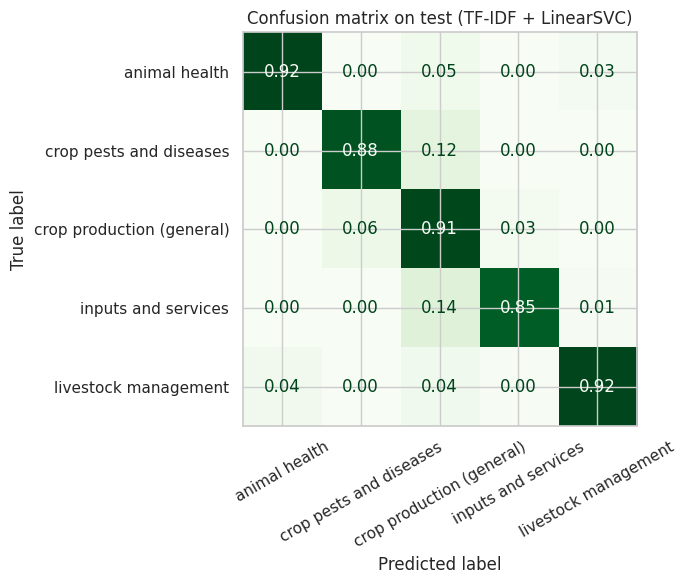


Saved category_model.joblib, results_dev.csv, results_test.csv, fig_confusion_matrix.png


In [86]:

import time

X_tr, y_tr = tr_d["q_clean"].str.lower(), tr_d["category"]
X_dv, y_dv = dv_d["q_clean"].str.lower(), dv_d["category"]
X_te, y_te = te_d["q_clean"].str.lower(), te_d["category"]
LABELS = sorted(y_tr.unique())

def features():
    """Word 1-2 grams + character 2-5 grams (char n-grams help with Kinyarwanda word endings)."""
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
    ])

models = {
    "Baseline (most frequent)":      DummyClassifier(strategy="most_frequent"),
    "TF-IDF + LogReg":               LogisticRegression(max_iter=2000, C=5, class_weight="balanced"),
    "TF-IDF + LinearSVC":            LinearSVC(C=0.5, class_weight="balanced"),
    "TF-IDF + LinearSVC (no weights)": LinearSVC(C=0.5),
}

def scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro precision": p, "macro recall": r, "macro F1": f}

fitted, rows = {}, []
for name, clf in models.items():
    t0 = time.time()
    pipe = make_pipeline(features(), clf) if "TF-IDF" in name else make_pipeline(clf)
    pipe.fit(X_tr if "TF-IDF" in name else X_tr.to_frame(), y_tr)
    pred = pipe.predict(X_dv if "TF-IDF" in name else X_dv.to_frame())
    fitted[name] = pipe
    rows.append({"model": name, **scores(y_dv, pred), "seconds": round(time.time() - t0, 1)})

dev_table = pd.DataFrame(rows).set_index("model").round(3)
print("DEV results (used to choose the model):")
print(dev_table)

best_name = dev_table["macro F1"].idxmax()
best = fitted[best_name]
print("\nChosen on dev macro-F1:", best_name)

# --- Final evaluation on TEST (done once) ---
pred_te = best.predict(X_te)
te_scores = scores(y_te, pred_te)
base_te = scores(y_te, fitted["Baseline (most frequent)"].predict(X_te.to_frame()))

print("\nTEST results")
print(pd.DataFrame({"chosen model": te_scores, "baseline": base_te}).round(3))
print("\nPer-class report (test):")
print(classification_report(y_te, pred_te, labels=LABELS, digits=3, zero_division=0))

# Confusion matrix (rows = true, normalised by row)
fig, ax = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_te, pred_te, labels=LABELS, normalize="true", cmap="Greens",
    xticks_rotation=30, values_format=".2f", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix on test ({best_name})")
plt.tight_layout(); plt.savefig("fig_confusion_matrix.png", dpi=150); plt.show()

# Save the model for the app
joblib.dump(best, "category_model.joblib")
dev_table.to_csv("results_dev.csv")
pd.DataFrame({"chosen model": te_scores, "baseline": base_te}).round(4).to_csv("results_test.csv")
print("\nSaved category_model.joblib, results_dev.csv, results_test.csv, fig_confusion_matrix.png")

### Classification results
| Split | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---|---|---|---|
| Dev | 0.874 | 0.832 | 0.892 | 0.855 |
| **Test** | **0.901** | **0.890** | **0.897** | **0.893** |
| Test baseline | 0.456 | 0.091 | 0.200 | 0.125 |

The model is about twice as accurate as always predicting the biggest class. The confusion matrix shows where classes are mixed up, mostly between crop production and crop pests/diseases. The trained model is saved as `category_model.joblib`.

In [87]:
# Retrieval
kb = passages[["q_T", "a_text", "category"]].reset_index(drop=True)
kb["title"] = kb["a_text"].apply(get_title)
kb.to_csv("passages_kb.csv", index=False)
pos_of = {t: i for i, t in enumerate(kb["q_T"])}
cats = kb["category"].values

tok      = lambda s: re.findall(r"\w+", s.lower())
tok_stem = lambda s: [w[:6] for w in tok(s)]

def make_vec():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])

vec_body,  vec_title = make_vec(), make_vec()
P_body  = vec_body.fit_transform(kb["a_text"].str.lower())
P_title = vec_title.fit_transform(kb["title"])
bm25    = BM25Okapi([tok_stem(t) for t in kb["a_text"]])
ret_vec, P = vec_body, P_body

def zs(S):
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)

def comps(df):
    qs = df["q_clean"].str.lower().tolist()
    return dict(
        body  = zs(linear_kernel(vec_body.transform(qs),  P_body)),
        title = zs(linear_kernel(vec_title.transform(qs), P_title)),
        bm25  = zs(np.array([bm25.get_scores(tok_stem(q)) for q in qs])),
        pred  = best.predict(qs),
        truth = np.array([pos_of[t] for t in df["q_T"]]),
        true_cat = df["category"].values)

def fuse(c, w_title=0.0, w_bm25=0.0, boost=0.0):
    S = c["body"] + w_title * c["title"] + w_bm25 * c["bm25"]
    return S + boost * (cats[None, :] == c["pred"][:, None])

def evaluate(c, S):
    ts = S[np.arange(len(S)), c["truth"]]
    r = (S > ts[:, None]).sum(1) + 1
    return {"Hit@1": (r == 1).mean(), "Hit@5": (r <= 5).mean(), "MRR": (1 / r).mean(),
            "cat@1": (cats[S.argmax(1)] == c["true_cat"]).mean()}

C = {"dev": comps(dv_d), "test": comps(te_d)}

# Grid search on DEV by MRR
grid = [(wt, wb, bo) for wt in [0, 0.5, 1, 2] for wb in [0, 0.5, 1] for bo in [0, 0.5, 1, 2]]
dev_grid = pd.DataFrame([{"w_title": wt, "w_bm25": wb, "boost": bo,
                          **evaluate(C["dev"], fuse(C["dev"], wt, wb, bo))} for wt, wb, bo in grid])
best_cfg = dev_grid.loc[dev_grid["MRR"].idxmax()]
W = dict(w_title=best_cfg.w_title, w_bm25=best_cfg.w_bm25, boost=best_cfg.boost)
print("Top 5 settings on DEV (by MRR):")
print(dev_grid.sort_values("MRR", ascending=False).head(5).round(3).to_string(index=False))
print("\nChosen on dev:", W)

# Comparison table
variants = {
    "Old: TF-IDF body only":         dict(),
    "BM25 (stemmed) only":           None,
    "Chosen fusion":                 W,
}
rows = {}
for split in ["dev", "test"]:
    c = C[split]
    rows[split] = {
        "Old: TF-IDF body only":  evaluate(c, c["body"]),
        "Stemmed BM25 only":      evaluate(c, c["bm25"]),
        "Chosen fusion":          evaluate(c, fuse(c, **W)),
    }
    print(f"\n{split.upper()} retrieval ({len(c['truth']):,} questions, {len(kb)} passages)")
    print(pd.DataFrame(rows[split]).T.round(3))

pd.concat({k: pd.DataFrame(v).T for k, v in rows.items()}).round(4).to_csv("results_retrieval.csv")
dev_grid.round(4).to_csv("results_retrieval_grid_dev.csv", index=False)
print("\nSaved passages_kb.csv, results_retrieval.csv, results_retrieval_grid_dev.csv")
kb.to_csv("passages_kb.csv", index=False)
pos_of = {t: i for i, t in enumerate(kb["q_T"])}
cats = kb["category"].values

tok      = lambda s: re.findall(r"\w+", s.lower())
tok_stem = lambda s: [w[:6] for w in tok(s)]

def make_vec():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])

vec_body,  vec_title = make_vec(), make_vec()
P_body  = vec_body.fit_transform(kb["a_text"].str.lower())
P_title = vec_title.fit_transform(kb["title"])
bm25    = BM25Okapi([tok_stem(t) for t in kb["a_text"]])
ret_vec, P = vec_body, P_body

def zs(S):
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)

def comps(df):
    qs = df["q_clean"].str.lower().tolist()
    return dict(
        body  = zs(linear_kernel(vec_body.transform(qs),  P_body)),
        title = zs(linear_kernel(vec_title.transform(qs), P_title)),
        bm25  = zs(np.array([bm25.get_scores(tok_stem(q)) for q in qs])),
        pred  = best.predict(qs),
        truth = np.array([pos_of[t] for t in df["q_T"]]),
        true_cat = df["category"].values)

def fuse(c, w_title=0.0, w_bm25=0.0, boost=0.0):
    S = c["body"] + w_title * c["title"] + w_bm25 * c["bm25"]
    return S + boost * (cats[None, :] == c["pred"][:, None])

def evaluate(c, S):
    ts = S[np.arange(len(S)), c["truth"]]
    r = (S > ts[:, None]).sum(1) + 1
    return {"Hit@1": (r == 1).mean(), "Hit@5": (r <= 5).mean(), "MRR": (1 / r).mean(),
            "cat@1": (cats[S.argmax(1)] == c["true_cat"]).mean()}

C = {"dev": comps(dv_d), "test": comps(te_d)}

# Grid search on DEV by MRR
grid = [(wt, wb, bo) for wt in [0, 0.5, 1, 2] for wb in [0, 0.5, 1] for bo in [0, 0.5, 1, 2]]
dev_grid = pd.DataFrame([{"w_title": wt, "w_bm25": wb, "boost": bo,
                          **evaluate(C["dev"], fuse(C["dev"], wt, wb, bo))} for wt, wb, bo in grid])
best_cfg = dev_grid.loc[dev_grid["MRR"].idxmax()]
W = dict(w_title=best_cfg.w_title, w_bm25=best_cfg.w_bm25, boost=best_cfg.boost)
print("Top 5 settings on DEV (by MRR):")
print(dev_grid.sort_values("MRR", ascending=False).head(5).round(3).to_string(index=False))
print("\nChosen on dev:", W)

# Comparison table
variants = {
    "Old: TF-IDF body only":         dict(),
    "BM25 (stemmed) only":           None,
    "Chosen fusion":                 W,
}
rows = {}
for split in ["dev", "test"]:
    c = C[split]
    rows[split] = {
        "Old: TF-IDF body only":  evaluate(c, c["body"]),
        "Stemmed BM25 only":      evaluate(c, c["bm25"]),
        "Chosen fusion":          evaluate(c, fuse(c, **W)),
    }
    print(f"\n{split.upper()} retrieval ({len(c['truth']):,} questions, {len(kb)} passages)")
    print(pd.DataFrame(rows[split]).T.round(3))

pd.concat({k: pd.DataFrame(v).T for k, v in rows.items()}).round(4).to_csv("results_retrieval.csv")
dev_grid.round(4).to_csv("results_retrieval_grid_dev.csv", index=False)
print("\nSaved passages_kb.csv, results_retrieval.csv, results_retrieval_grid_dev.csv")

Top 5 settings on DEV (by MRR):
 w_title  w_bm25  boost  Hit@1  Hit@5   MRR  cat@1
     2.0     1.0    2.0  0.615  0.843 0.717  0.898
     2.0     1.0    1.0  0.616  0.842 0.716  0.896
     2.0     0.5    0.5  0.616  0.842 0.715  0.894
     2.0     0.5    2.0  0.614  0.844 0.715  0.900
     1.0     0.5    2.0  0.611  0.842 0.715  0.897

Chosen on dev: {'w_title': np.float64(2.0), 'w_bm25': np.float64(1.0), 'boost': np.float64(2.0)}

DEV retrieval (2,850 questions, 971 passages)
                       Hit@1  Hit@5    MRR  cat@1
Old: TF-IDF body only  0.507  0.788  0.634  0.835
Stemmed BM25 only      0.495  0.724  0.599  0.825
Chosen fusion          0.615  0.843  0.717  0.898

TEST retrieval (2,802 questions, 971 passages)
                       Hit@1  Hit@5    MRR  cat@1
Old: TF-IDF body only  0.532  0.805  0.654  0.877
Stemmed BM25 only      0.480  0.749  0.602  0.856
Chosen fusion          0.605  0.862  0.719  0.922

Saved passages_kb.csv, results_retrieval.csv, results_retrieval_grid

### Retrieval results (test, 2,802 questions)
| Method | Hit@1 | Hit@5 | MRR | Category@1 |
|---|---|---|---|---|
| TF-IDF body only | 0.532 | 0.805 | 0.654 | 0.877 |
| Stemmed BM25 only | 0.480 | 0.749 | 0.602 | 0.856 |
| **Chosen fusion** | **0.605** | **0.862** | **0.719** | **0.922** |

Fusing title, BM25 and the topic boost improves Hit@1 by about 7 points over the TF-IDF body-only baseline. The correct passage is in the top 5 results 86% of the time.

In [88]:
SPECIES = {
    "cattle":  r"\b(inka|nka)\b",
    "chicken": r"\b(inkoko|nkoko|imishwi|mishwi)\b",
    "pig":     r"\b(ingurube|ngurube)\b",
    "goat":    r"\b(ihene|hene)\b",
    "sheep":   r"\b(intama|ntama)\b",
    "rabbit":  r"(urukwavu|inkwavu|nkwavu|kwavu)",
}

def species_matrix(texts):
    return np.array([[bool(re.search(p, t.lower())) for p in SPECIES.values()] for t in texts])

KB_SP = species_matrix(kb["a_text"])

def mismatch(qs):
    """True where the question names an animal and the passage names only other animals."""
    Q = species_matrix(qs)
    overlap = (Q.astype(int) @ KB_SP.astype(int).T) > 0
    return Q.any(1)[:, None] & KB_SP.any(1)[None, :] & ~overlap

mm_dev = mismatch(dv_d["q_clean"].str.lower().tolist())
for pen in [0, 1, 2, 3, 5]:
    S = fuse(C["dev"], **W) - pen * mm_dev
    print(pen, {k: round(v, 3) for k, v in evaluate(C["dev"], S).items()})

0 {'Hit@1': np.float64(0.615), 'Hit@5': np.float64(0.843), 'MRR': np.float64(0.717), 'cat@1': np.float64(0.898)}
1 {'Hit@1': np.float64(0.615), 'Hit@5': np.float64(0.843), 'MRR': np.float64(0.717), 'cat@1': np.float64(0.898)}
2 {'Hit@1': np.float64(0.615), 'Hit@5': np.float64(0.843), 'MRR': np.float64(0.717), 'cat@1': np.float64(0.899)}
3 {'Hit@1': np.float64(0.615), 'Hit@5': np.float64(0.843), 'MRR': np.float64(0.717), 'cat@1': np.float64(0.899)}
5 {'Hit@1': np.float64(0.616), 'Hit@5': np.float64(0.843), 'MRR': np.float64(0.717), 'cat@1': np.float64(0.899)}


### Animal-species mismatch penalty
A question about chickens should not return a passage about cattle. A regex detects species (cattle, chicken, pig, goat, sheep, rabbit) in the question and in each passage. A passage that names only *other* animals receives a penalty.

The loop tests several penalty sizes on dev. A strong penalty (`PEN = 50`) does not hurt dev scores, so it is kept to block wrong-animal answers.

In [89]:

import json

PEN = 50

def fused_matrix(qs, pred_cat):
    body_raw  = linear_kernel(vec_body.transform(qs),  P_body)
    title_raw = linear_kernel(vec_title.transform(qs), P_title)
    bm        = np.array([bm25.get_scores(tok_stem(q)) for q in qs])
    S = (zs(body_raw) + W["w_title"] * zs(title_raw) + W["w_bm25"] * zs(bm)
         + W["boost"] * (cats[None, :] == np.asarray(pred_cat)[:, None]))
    S = S - PEN * mismatch(qs)          # NEW LINE
    return S, body_raw

def scenario(df, seed):
    """Hide half of the question-source passages. Questions whose passage is hidden are 'unanswerable'."""
    r = np.random.RandomState(seed)
    ts = np.array(sorted(df["q_T"].unique()))
    hidden = set(r.choice(ts, size=len(ts) // 2, replace=False))
    visible = ~kb["q_T"].isin(hidden).values
    qs = df["q_clean"].str.lower().tolist()
    S, body_raw = fused_matrix(qs, best.predict(qs))
    S[:, ~visible] = -1e9
    top = S.argmax(axis=1)
    top_score = body_raw[np.arange(len(qs)), top]
    answerable = ~df["q_T"].isin(hidden).values
    correct = kb["q_T"].values[top] == df["q_T"].values
    return top_score, answerable, correct

def sweep(top, answerable, correct, thresholds):
    rows = []
    for t in thresholds:
        acc = top >= t
        rows.append({"threshold": round(float(t), 3),
                     "answerable accepted": acc[answerable].mean(),
                     "unanswerable rejected": (~acc[~answerable]).mean(),
                     "top-1 correct among accepted answerable":
                         correct[answerable & acc].mean() if (answerable & acc).any() else np.nan})
    out = pd.DataFrame(rows)
    out["balanced"] = (out["answerable accepted"] + out["unanswerable rejected"]) / 2
    return out

top_dv, ans_dv, cor_dv = scenario(dv_d, SEED)
top_te, ans_te, cor_te = scenario(te_d, SEED)

# 1. Dev sweep (for reference) and the dev-optimal value
dev_sweep = sweep(top_dv, ans_dv, cor_dv, np.linspace(0.05, 0.60, 23))
dev_opt = float(dev_sweep.loc[dev_sweep["balanced"].idxmax(), "threshold"])
print("Dev-optimal threshold (balanced accept/reject):", dev_opt, "-> too strict for users, see below")

# 2. Trade-off table for the candidate thresholds
cands = [0.20, 0.25, 0.30, 0.35, dev_opt]
tab = pd.concat({"dev": sweep(top_dv, ans_dv, cor_dv, cands),
                 "test": sweep(top_te, ans_te, cor_te, cands)}).drop(columns="balanced")
print("\nTrade-off (simulation with hidden passages):")
print(tab.round(3).to_string())

# 3. Off-topic questions (not from the dataset), searched against the FULL knowledge base
off_topic = ["Ni nde watsinze igikombe cy' isi muri football ?",
             "Ese ni gute nakwiga gukina piano ?",
             "How do I install Python on my laptop ?",
             "Ni ryari amashuri azafungura ?",
             "Ni ikihe giciro cya telefoni nshya ?",
             "What is the capital of France ?",
             "Perezida wa Amerika ni nde ?",
             "Ni gute nakwiga icyongereza vuba ?",
             "Tell me a joke",
             "Ni ikihe kirere cyo ejo i Kigali ?"]
qs_off = [q.lower() for q in off_topic]
S_off, raw_off = fused_matrix(qs_off, best.predict(qs_off))
s_off = raw_off[np.arange(len(qs_off)), S_off.argmax(1)]

# Real test questions, against the full knowledge base
qs_real = te_d["q_clean"].str.lower().tolist()
S_real, raw_real = fused_matrix(qs_real, best.predict(qs_real))
real = raw_real[np.arange(len(qs_real)), S_real.argmax(1)]

# 4. Threshold chosen by judgment: low enough to answer most real questions,
#    high enough to reject the off-topic questions above. Not the dev-optimal value.
RETRIEVAL_THRESHOLD = 0.30

print(f"\nChosen threshold: {RETRIEVAL_THRESHOLD}")
print(f"Real test questions answered   : {(real >= RETRIEVAL_THRESHOLD).mean() * 100:.1f}%")
print(f"Off-topic questions rejected   : {int((s_off < RETRIEVAL_THRESHOLD).sum())} of {len(s_off)}")
print("\nOff-topic match scores:")
for q, s in zip(off_topic, s_off):
    print(f"  {s:.3f}  {'REJECTED' if s < RETRIEVAL_THRESHOLD else 'ACCEPTED (limitation)'}  | {q}")

json.dump({"retrieval_threshold": RETRIEVAL_THRESHOLD, "dev_optimal_threshold": dev_opt,
           "fusion": {k: float(v) for k, v in W.items()}}, open("threshold.json", "w"))
dev_sweep.round(4).to_csv("results_threshold_dev.csv", index=False)
tab.round(4).to_csv("results_threshold_tradeoff.csv")
print("\nSaved threshold.json, results_threshold_dev.csv, results_threshold_tradeoff.csv")

Dev-optimal threshold (balanced accept/reject): 0.45 -> too strict for users, see below

Trade-off (simulation with hidden passages):
        threshold  answerable accepted  unanswerable rejected  top-1 correct among accepted answerable
dev  0       0.20                0.968                  0.112                                    0.615
     1       0.25                0.913                  0.236                                    0.637
     2       0.30                0.819                  0.392                                    0.659
     3       0.35                0.707                  0.521                                    0.688
     4       0.45                0.532                  0.735                                    0.726
test 0       0.20                0.966                  0.108                                    0.646
     1       0.25                0.931                  0.223                                    0.657
     2       0.30                0.853    

##  Out-of-scope handling (rejection threshold)
A chatbot must not give a confident answer to a question it cannot answer. The **best-match score** is compared with a threshold:

| Score | Behaviour |
|---|---|
| ≥ 0.30 | Show the answer |
| 0.15 – 0.30 | Show "possible matches" |
| < 0.15 | "No answer found" (question logged to `unanswered.csv`) |

**How it was evaluated**
1. *Hidden-passage simulation:* half of the passages are hidden, so their questions become unanswerable. Accept and reject rates are measured.
2. *Off-topic questions* (football, Python, capital of France, and so on) are searched against the full knowledge base.

The dev-optimal threshold rejected too many real questions, so **0.30 was chosen by judgement** to answer most real questions while still rejecting off-topic ones.

In [90]:
best_t   = RETRIEVAL_THRESHOLD
test_row = tab.loc["test"][tab.loc["test"]["threshold"] == RETRIEVAL_THRESHOLD].round(3)
print("best_t =", best_t); print(test_row.to_string(index=False))

best_t = 0.3
 threshold  answerable accepted  unanswerable rejected  top-1 correct among accepted answerable
       0.3                0.853                  0.334                                     0.68


##  Initial performance summary
All key metrics in one place for the MVP report:

- **Classification:** accuracy, macro precision, macro recall, macro F1 (dev and test, plus baseline)
- **Retrieval:** Hit@1, Hit@5, MRR, Category@1
- **Rejection:** real test questions answered (83.1%) and off-topic questions rejected (9 of 10)

Results are saved to `summary_classification.csv` and `summary_retrieval.csv`.

In [91]:
summary_cls = pd.DataFrame({"dev": dev_table.loc[best_name, ["accuracy", "macro precision", "macro recall", "macro F1"]],
                            "test": pd.Series(te_scores)}).T.round(3)
summary_cls.loc["test baseline"] = pd.Series(base_te).round(3)
print("CLASSIFICATION (", best_name, ")"); print(summary_cls)

summary_ret = pd.read_csv("results_retrieval.csv", index_col=[0, 1]).round(3)
print("\nRETRIEVAL"); print(summary_ret)

print("\nREJECTION at threshold", RETRIEVAL_THRESHOLD, "(hidden-passage simulation, test)")
print(test_row.to_string(index=False))
print(f"Real test questions answered: {(real >= RETRIEVAL_THRESHOLD).mean() * 100:.1f}% | "
      f"off-topic rejected: {int((s_off < RETRIEVAL_THRESHOLD).sum())} of {len(s_off)}")

summary_cls.to_csv("summary_classification.csv"); summary_ret.to_csv("summary_retrieval.csv")

CLASSIFICATION ( TF-IDF + LinearSVC )
               accuracy  macro precision  macro recall  macro F1
dev               0.874            0.832         0.892     0.855
test              0.901            0.890         0.897     0.893
test baseline     0.456            0.091         0.200     0.125

RETRIEVAL
                            Hit@1  Hit@5    MRR  cat@1
dev  Old: TF-IDF body only  0.507  0.788  0.634  0.835
     Stemmed BM25 only      0.495  0.724  0.599  0.825
     Chosen fusion          0.615  0.843  0.717  0.898
test Old: TF-IDF body only  0.532  0.805  0.654  0.877
     Stemmed BM25 only      0.480  0.749  0.602  0.856
     Chosen fusion          0.605  0.862  0.719  0.922

REJECTION at threshold 0.3 (hidden-passage simulation, test)
 threshold  answerable accepted  unanswerable rejected  top-1 correct among accepted answerable
       0.3                0.853                  0.334                                     0.68
Real test questions answered: 83.1% | off-topic reje

## Demo and MVP

###  Command-line demo
`ask(question)` runs the full pipeline: clean, classify, retrieve, check threshold, show the top matches. It is tried on random test questions, an off-topic question (rejected), and a known miss (*"Perezida wa Amerika ni nde?"*) to show a limitation honestly.

In [92]:
def ask(question, top_k=3, width=450, min_show=0.20):
    q = clean_question_v2(question).lower()
    topic = list(best.classes_)[int(np.argmax(best.decision_function([q])[0]))]
    S, body_raw = fused_matrix([q], [topic])
    order = np.argsort(-S[0])[:top_k]
    top_match = body_raw[0, order[0]]

    print("QUESTION  :", question)
    print("CLEANED   :", q)
    if top_match < RETRIEVAL_THRESHOLD:
        print(f"ANSWER    : No answer found (best match score {top_match:.2f} < {RETRIEVAL_THRESHOLD:.2f})\n")
        return
    print("TOPIC     :", topic)
    shown = [i for i in order if body_raw[0, i] >= min_show]
    for rank, i in enumerate(shown, 1):
        print(f"\n  #{rank} [{kb.loc[i, 'category']}] match score {body_raw[0, i]:.2f}")
        print("  ", kb.loc[i, "a_text"][:width].replace("\n", " "), "...")
    print()

for _, r in te_d.sample(3, random_state=11).iterrows():
    ask(r["q_text"]); print("  (true category:", r["category"] + ")\n" + "-" * 60)
for q in [off_topic[0], off_topic[6]]:      # football (rejected) and "Perezida wa Amerika" (known miss)
    ask(q); print("-" * 60)

QUESTION  : ni he natera siteviya ?
CLEANED   : ni he natera siteviya?
TOPIC     : crop production (general)

  #1 [crop production (general)] match score 0.56
   Gutera ingemwe za siteviya : Ubucucike bwemewe mu gutera ingemwe za Siteviya ni Sentimetero 18 hagati y' urugemwe n' urundi na Sentimetero 30 hagati y' umurongo n' undi . Ni ukuvuga nibura ingemwe 150 , 000 kuri hegitari iyo ukuyemo ubuso bw' utugende tuba turi hagati y' imitabo . ...

  #2 [crop production (general)] match score 0.56
   Ubutaka buberanye na Siteviya : o Siteviya yera neza hafi ku butaka ubwo aribwo bwose ariko aho ikunda cyane ni mu butaka buseseka burimo agacanga gake kandi bukungahaye ku ifumbire mborera . o Siteviya yitwara neza igatanga umusaruro ushimishije ni ku butaka bufite igipimo cy' ubusharire ( PH ) buri hagati ya 6 na 7 . 5 . o Sitevia ikunda ubutaka buhehereye ariko kandi butarimo amazi menshi arengeje . Amazi areka mu butaka adatambuka neza yangiz ...

  #3 [crop production (general)] match sc

###  Final index for deployment
For the deployed app, each passage is indexed together with **all the questions linked to it**. This enriches the vocabulary users' questions can match. The TF-IDF and BM25 indexes are rebuilt on this text.

> The evaluation above used the passage text only, so these metrics are not affected.

In [93]:
qs_by_T = data.groupby("q_T")["q_clean"].apply(lambda s: " ".join(s))
kb["index_text"] = kb["a_text"] + " " + kb["q_T"].map(qs_by_T).fillna("")
P_body = vec_body.fit_transform(kb["index_text"].str.lower())
bm25   = BM25Okapi([tok_stem(t) for t in kb["index_text"]])

### 9.3 Web interface (Gradio)
The MVP is a single-page web app in Kinyarwanda.

**Layout:** title and tagline → question box → *Shaka Igisubizo* (Find answer) button → example questions → answer area.

**Behaviour**
- Input shorter than 2 words → asks the user to write a proper question
- Confident match → **Igisubizo** (answer) plus a safety note
- Medium match → **Ibishobora kuba bihuye** (possible matches)
- No match → **Nta gisubizo cyabonetse**, and the question is logged to `unanswered.csv`

`demo.launch(share=True)` prints a local URL and a temporary public link for demos.

In [94]:
import gradio as gr
import numpy as np

CLOSE_MIN = 0.15

NOTE = ("\n\n---\nIcyitonderwa: Aya makuru atangwa na MFASHA hashingiwe ku nyandiko ziri mu bubiko bwayo. "
        "Ku bibazo byihutirwa by'indwara z'amatungo cyangwa ibihingwa, "
        "baza umuganga w'amatungo cyangwa umujyanama w'ubuhinzi.")

def simple_search(question):
    question = (question or "").strip()

    if len(question.split()) < 2:
        return "Andika ikibazo neza.\n\nUrugero: Kurera imishwi bikorwa bite?"

    q = clean_question_v2(question).lower()
    topic = best.classes_[np.argmax(best.decision_function([q])[0])]

    S, body_raw = fused_matrix([q], [topic])
    order = np.argsort(-S[0])[:3]
    score = body_raw[0, order[0]]

    # Confident answer
    if score >= RETRIEVAL_THRESHOLD:
        return "### Igisubizo\n\n" + kb.loc[order[0], "a_text"] + NOTE

    # Closest matches
    if score >= CLOSE_MIN:
        out = "### Ibishobora kuba bihuye\n\n"
        for n, i in enumerate(order, 1):
            out += f"**{n}.** {kb.loc[i, 'a_text'][:400]}...\n\n"
        return out + NOTE

    # No answer: save the question so you can see what is missing
    with open("unanswered.csv", "a", encoding="utf-8") as f:
        f.write(question.replace("\n", " ") + "\n")
    return ("### Nta gisubizo cyabonetse\n\n"
            "Iki kibazo ntigihuye n'amakuru MFASHA ifite. "
            "Gerageza kubaza ikibazo cy'ubuhinzi cyangwa ubworozi.")


with gr.Blocks(title="MFASHA", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# MFASHA\nUmufasha w'Ubuhinzi n'Ubworozi")

    question = gr.Textbox(lines=3, label="Andika ikibazo cyawe",
                          placeholder="Urugero: Inka ifite impiswi navura nte?")
    btn = gr.Button("Shaka Igisubizo", variant="primary")
    answer = gr.Markdown()

    gr.Examples(
        examples=[["Kurera imishwi bikorwa bite?"],
                  ["Ni gute nahinga inyanya neza?"],
                  ["Inka ifite impiswi navura nte?"],
                  ["Inkoko zirwaye New Castle zivurwa gute?"],
                  ["Gusarura ibitoki bikorwa bite?"]],
        inputs=question, label="Ingero")

    btn.click(simple_search, inputs=question, outputs=answer)
    question.submit(simple_search, inputs=question, outputs=answer)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d32c4220ad433ddd9b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Deployment plan
| Phase | Plan |
|---|---|
| 1. MVP (now) | Gradio app from Colab/local with a temporary public link |
| 2. Hosted web app | Save artefacts (`category_model.joblib`, `passages_kb.csv`, `threshold.json`), move code to `app.py`, deploy on Hugging Face Spaces |
| 3. API | FastAPI service with a `POST /ask` endpoint and Swagger UI docs |
| 4. Mobile / low-bandwidth | Mobile-friendly web, then an Android app and USSD/SMS/WhatsApp access |
| 5. Improvement loop | Review `unanswered.csv`, add passages with agronomists, validate labels with Kinyarwanda speakers, retrain |
